# Project 1: DCGAN on MNIST

# Step 1: Setup

In [7]:
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import os
from tqdm import tqdm

# Ensure GPU is detected
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available: 1


# Step 2: Load and preprocess MNIST

In [8]:
(X_train, _), (_, _) = tf.keras.datasets.mnist.load_data()
X_train = (X_train - 127.5) / 127.5  # normalize to [-1,1]
X_train = np.expand_dims(X_train, axis=-1)  # (60000, 28, 28, 1)
BUFFER_SIZE = 60000
BATCH_SIZE = 128

dataset = tf.data.Dataset.from_tensor_slices(X_train).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

# Step 3: Generator

In [9]:
def build_generator():
    model = tf.keras.Sequential([
        layers.Dense(7*7*256, use_bias=False, input_shape=(100,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        
        layers.Reshape((7, 7, 256)),
        
        layers.Conv2DTranspose(128, (5,5), strides=(1,1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        
        layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        
        layers.Conv2DTranspose(1, (5,5), strides=(2,2), padding='same', use_bias=False, activation='tanh')
    ])
    return model
generator = build_generator()

# Step 4: Discriminator

In [10]:
def build_discriminator():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5,5), strides=(2,2), padding='same', input_shape=[28,28,1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        
        layers.Conv2D(128, (5,5), strides=(2,2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        
        layers.Flatten(),
        layers.Dense(1)  # No activation (we’ll use logits)
    ])
    return model

discriminator = build_discriminator()

# Step 5: Losses & Optimizers

In [11]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output)*0.9, real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)


# Step 6: Training loop


Epoch 1/500


100%|██████████| 469/469 [00:14<00:00, 32.39it/s]


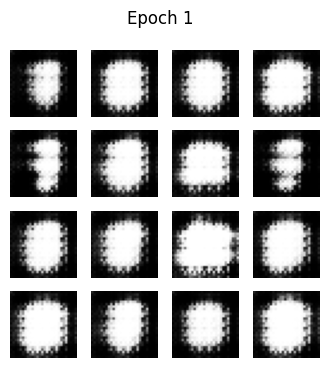


Epoch 2/500


100%|██████████| 469/469 [00:07<00:00, 62.46it/s]



Epoch 3/500


100%|██████████| 469/469 [00:07<00:00, 62.42it/s]



Epoch 4/500


100%|██████████| 469/469 [00:07<00:00, 62.41it/s]


... (88 outputs left out)


Epoch 49/500


100%|██████████| 469/469 [00:07<00:00, 62.50it/s]



Epoch 50/500


100%|██████████| 469/469 [00:07<00:00, 62.56it/s]


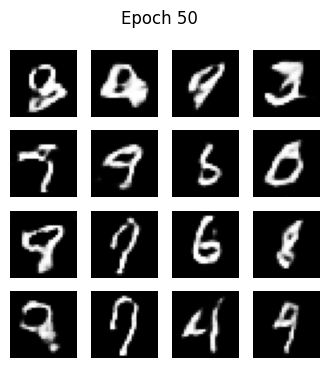


Epoch 51/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]



Epoch 52/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]



Epoch 53/500


100%|██████████| 469/469 [00:07<00:00, 62.47it/s]


... (90 outputs left out)


Epoch 99/500


100%|██████████| 469/469 [00:07<00:00, 62.52it/s]



Epoch 100/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]


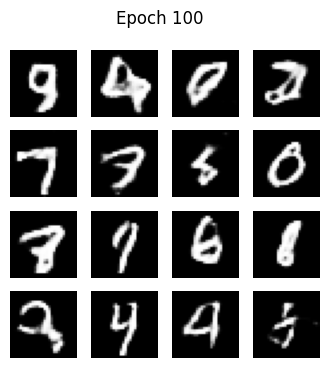


Epoch 101/500


100%|██████████| 469/469 [00:07<00:00, 62.52it/s]



Epoch 102/500


100%|██████████| 469/469 [00:07<00:00, 62.47it/s]



Epoch 103/500


100%|██████████| 469/469 [00:07<00:00, 62.46it/s]


... (90 outputs left out)


Epoch 149/500


100%|██████████| 469/469 [00:07<00:00, 62.53it/s]



Epoch 150/500


100%|██████████| 469/469 [00:07<00:00, 62.48it/s]


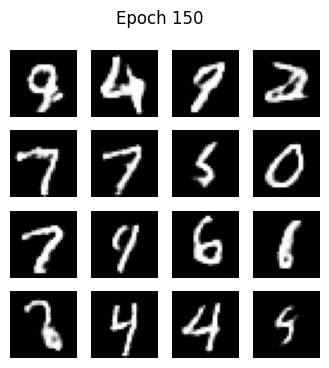


Epoch 151/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]



Epoch 152/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]



Epoch 153/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]


... (90 outputs left out)


Epoch 199/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]



Epoch 200/500


100%|██████████| 469/469 [00:07<00:00, 62.48it/s]


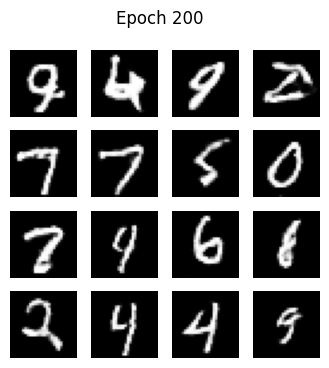


Epoch 201/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]



Epoch 202/500


100%|██████████| 469/469 [00:07<00:00, 62.52it/s]



Epoch 203/500


100%|██████████| 469/469 [00:07<00:00, 62.44it/s]


... (90 outputs left out)


Epoch 249/500


100%|██████████| 469/469 [00:07<00:00, 62.45it/s]



Epoch 250/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]


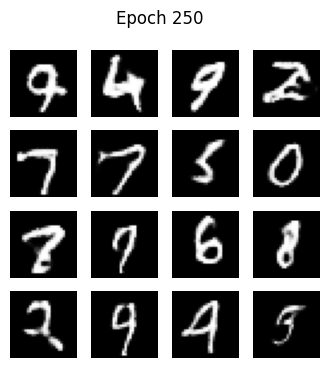


Epoch 251/500


100%|██████████| 469/469 [00:07<00:00, 62.44it/s]



Epoch 252/500


100%|██████████| 469/469 [00:07<00:00, 62.44it/s]



Epoch 253/500


100%|██████████| 469/469 [00:07<00:00, 62.43it/s]


... (90 outputs left out)


Epoch 299/500


100%|██████████| 469/469 [00:07<00:00, 62.50it/s]



Epoch 300/500


100%|██████████| 469/469 [00:07<00:00, 62.50it/s]


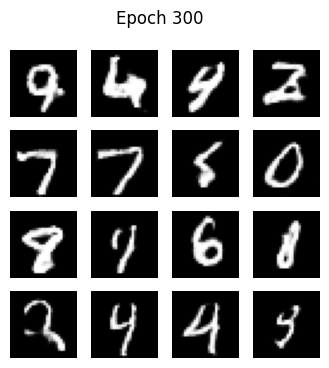


Epoch 301/500


100%|██████████| 469/469 [00:07<00:00, 62.46it/s]



Epoch 302/500


100%|██████████| 469/469 [00:07<00:00, 62.48it/s]



Epoch 303/500


100%|██████████| 469/469 [00:07<00:00, 62.50it/s]


... (90 outputs left out)


Epoch 349/500


100%|██████████| 469/469 [00:07<00:00, 62.45it/s]



Epoch 350/500


100%|██████████| 469/469 [00:07<00:00, 62.47it/s]


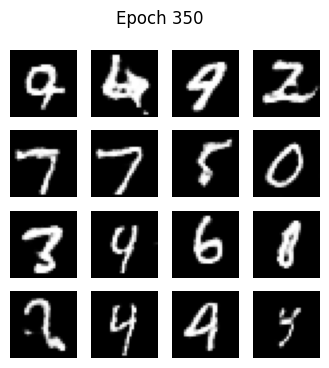


Epoch 351/500


100%|██████████| 469/469 [00:07<00:00, 62.43it/s]



Epoch 352/500


100%|██████████| 469/469 [00:07<00:00, 62.45it/s]



Epoch 353/500


100%|██████████| 469/469 [00:07<00:00, 62.51it/s]


... (90 outputs left out)


Epoch 399/500


100%|██████████| 469/469 [00:07<00:00, 62.50it/s]



Epoch 400/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]


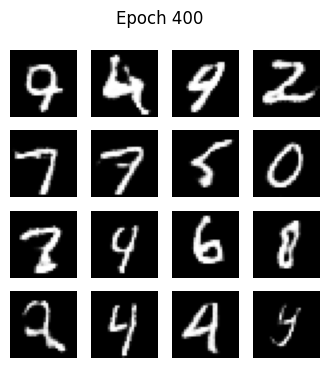


Epoch 401/500


100%|██████████| 469/469 [00:07<00:00, 62.47it/s]



Epoch 402/500


100%|██████████| 469/469 [00:07<00:00, 62.51it/s]



Epoch 403/500


100%|██████████| 469/469 [00:07<00:00, 62.47it/s]


... (90 outputs left out)


Epoch 449/500


100%|██████████| 469/469 [00:07<00:00, 62.45it/s]



Epoch 450/500


100%|██████████| 469/469 [00:07<00:00, 62.46it/s]


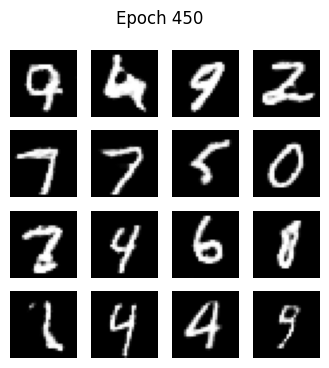


Epoch 451/500


100%|██████████| 469/469 [00:07<00:00, 62.49it/s]



Epoch 452/500


100%|██████████| 469/469 [00:07<00:00, 62.47it/s]



Epoch 453/500


100%|██████████| 469/469 [00:07<00:00, 62.46it/s]


... (90 outputs left out)


Epoch 499/500


100%|██████████| 469/469 [00:07<00:00, 62.45it/s]



Epoch 500/500


100%|██████████| 469/469 [00:07<00:00, 62.47it/s]


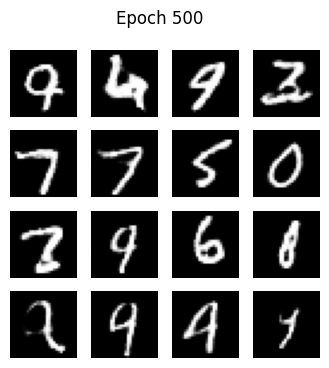

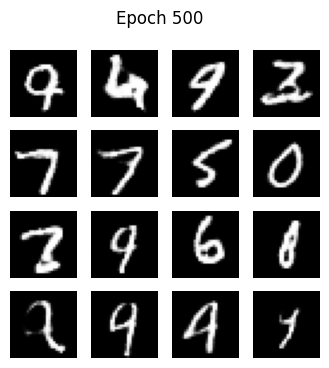

In [12]:
EPOCHS = 500
noise_dim = 100
num_examples_to_generate = 16

seed = tf.random.normal([num_examples_to_generate, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])
    
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)
        
        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)
        
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)
    
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    fig = plt.figure(figsize=(4,4))
    
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(predictions[i, :, :, 0] * 127.5 + 127.5, cmap='gray')
        plt.axis('off')
    
    plt.suptitle(f"Epoch {epoch}")
    plt.show()

def train(dataset, epochs):
    for epoch in range(1, epochs+1):
        print(f"\nEpoch {epoch}/{epochs}")
        for image_batch in tqdm(dataset):
            gen_loss, disc_loss = train_step(image_batch)
        
        # Generate images every few epochs
        if epoch % 50 == 0 or epoch == 1:
            generate_and_save_images(generator, epoch, seed)

train(dataset, EPOCHS)

# Final image generation
generate_and_save_images(generator, EPOCHS, seed)